## 0. Загрузка файлов

In [4]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving для модели — копия.csv to для модели — копия.csv
['для модели\xa0— копия.csv']


In [5]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving golden_set.jsonl to golden_set.jsonl
['golden_set.jsonl']


## 0. Переименование файлов

In [6]:
import os
for name in os.listdir():
    if name.endswith(".csv"):
        os.rename(name, "manifest.csv")
    if name.endswith(".jsonl"):
        os.rename(name, "golden_set.jsonl")
print(os.listdir())

['.config', 'manifest.csv', 'golden_set.jsonl', 'sample_data']


## 1. Данные
Скачиваем 400 фото по ссылкам из manifest.csv и читаем эталонную разметку (golden). Должно быть 400 фото и 509 рамок, из них 60 фото без бабочек.

In [14]:
import pandas as pd, json, os, requests

manifest = pd.read_csv("manifest.csv")
os.makedirs("images", exist_ok=True)

for i, row in manifest.iterrows():
    path = "images/" + str(row["photo_id"]) + ".jpg"
    if not os.path.exists(path):
        r = requests.get(row["image_url"], timeout=60)
        open(path, "wb").write(r.content)

golden = {}
for line in open("golden_set.jsonl"):
    rec = json.loads(line)
    golden[rec["photo_id"]] = rec["boxes"]

print("фото:", len(os.listdir("images")))
print("golden:", len(golden), "фото,", sum(len(b) for b in golden.values()), "рамок")

фото: 400
golden: 400 фото, 509 рамок


## 2. Метрика
IoU показывает, насколько две рамки совпадают (1 значит полностью, 0 значит не пересекаются).
На каждом фото ищем максимум пар "эталон + рамка модели" с IoU от 0.5, каждая рамка
только в одной паре. TP это пары, FP лишние рамки модели, FN пропущенные бабочки.
Суммируем по всем фото и считаем F1.
Проверка: эталон против самого себя дает F1 = 1.

2.1. IoU: насколько две рамки совпадают

In [8]:
def iou(a, b):
    # рамка: left, top, width, height (в долях от 0 до 1)
    ax2, ay2 = a["left"] + a["width"], a["top"] + a["height"]
    bx2, by2 = b["left"] + b["width"], b["top"] + b["height"]

    # пересечение
    w = min(ax2, bx2) - max(a["left"], b["left"])
    h = min(ay2, by2) - max(a["top"], b["top"])
    if w <= 0 or h <= 0:
        return 0.0
    inter = w * h

    # объединение = площадь A + площадь B - пересечение
    union = a["width"] * a["height"] + b["width"] * b["height"] - inter
    return inter / union

# проверка
A = {"left": 0.0, "top": 0.0, "width": 0.4, "height": 0.4}
B = {"left": 0.1, "top": 0.0, "width": 0.4, "height": 0.4}
print(iou(A, A))   # 1.0: совпадают
print(iou(A, B))   # 0.6: сдвинута на четверть

1.0
0.6


2.2. Сопоставление рамок на одном фото

In [9]:
import numpy as np
from scipy.optimize import linear_sum_assignment

def count_on_photo(gt_boxes, pred_boxes, thr=0.5):
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return 0, len(pred_boxes), len(gt_boxes)   # TP, FP, FN

    # таблица IoU: строки: эталонные рамки, столбцы: рамки модели
    m = np.array([[iou(g, p) for p in pred_boxes] for g in gt_boxes])
    good = (m >= thr).astype(int)

    # ищем максимальное число пар, каждая рамка: максимум в одной паре
    rows, cols = linear_sum_assignment(good, maximize=True)
    tp = int(good[rows, cols].sum())
    return tp, len(pred_boxes) - tp, len(gt_boxes) - tp

# проверка на одном фото: модель = эталон -> все попадания
pid = list(golden)[0]
print(pid, "рамок:", len(golden[pid]), "→", count_on_photo(golden[pid], golden[pid]))

367623 рамок: 21 → (21, 0, 0)


2.3. F1 по всему набору

In [10]:
def evaluate(preds, thr=0.5):
    TP = FP = FN = 0
    for pid in golden:
        tp, fp, fn = count_on_photo(golden[pid], preds.get(pid, []), thr)
        TP += tp; FP += fp; FN += fn
    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = 2 * TP / (2 * TP + FP + FN)
    return {"F1": round(f1, 3), "P": round(precision, 3), "R": round(recall, 3),
            "TP": TP, "FP": FP, "FN": FN}

print(evaluate(golden))      # эталон против самого себя -> F1 = 1.0
print(evaluate({}))          # модель ничего не нашла -> F1 = 0

{'F1': 1.0, 'P': 1.0, 'R': 1.0, 'TP': 509, 'FP': 0, 'FN': 0}
{'F1': 0.0, 'P': 0, 'R': 0.0, 'TP': 0, 'FP': 0, 'FN': 509}


## 3. Qwen3-VL-2B, строгий промпт
Модель получает только картинку и текст, отвечает координатами в JSON (шкала 0-1000).
Используем float16: на T4 это 2-3 с на фото (с bfloat16 было 28 с).
Версия весов зафиксирована. Фото уменьшаем до 1024 px.

3.1. Загрузка модели и функция поиска

In [11]:
import torch, re, time
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

QWEN = "Qwen/Qwen3-VL-2B-Instruct"
QWEN_REV = "89644892e4d85e24eaac8bacfd4f463576704203"   # та же версия весов, что 15 ноября

model = AutoModelForImageTextToText.from_pretrained(QWEN, revision=QWEN_REV, dtype=torch.float16).to("cuda")
processor = AutoProcessor.from_pretrained(QWEN, revision=QWEN_REV)

PROMPT = ("Find every adult butterfly in the image. Give each butterfly its own tight box around "
          "the visible wings, body and antennae; if butterflies overlap, still box each one separately. "
          "Do NOT box moths, caterpillars, pupae, other insects, shadows or flowers. "
          "Output JSON only: [{\"bbox_2d\": [x1, y1, x2, y2], \"label\": \"butterfly\"}]. "
          "If there is no adult butterfly, output [].")

def qwen_find(path):
    img = Image.open(path).convert("RGB")
    img.thumbnail((1024, 1024))          # уменьшаем большие фото: быстрее, координаты всё равно относительные

    messages = [{"role": "user", "content": [{"type": "image", "image": img},
                                             {"type": "text", "text": PROMPT}]}]
    inputs = processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
                                           return_dict=True, return_tensors="pt").to("cuda")
    out = model.generate(**inputs, max_new_tokens=512, do_sample=False)
    text = processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]

    # вытаскиваем все "bbox_2d": [x1, y1, x2, y2]; координаты Qwen: от 0 до 1000
    boxes = []
    for nums in re.findall(r'"bbox_2d"\s*:\s*\[([^\]]+)\]', text):
        v = [float(x) for x in nums.split(",")]
        if len(v) != 4:
            continue
        x1, x2 = sorted([v[0], v[2]])
        y1, y2 = sorted([v[1], v[3]])
        x1, y1, x2, y2 = [min(max(c / 1000, 0), 1) for c in (x1, y1, x2, y2)]
        if x2 - x1 > 0 and y2 - y1 > 0:
            boxes.append({"left": x1, "top": y1, "width": x2 - x1, "height": y2 - y1})
    return boxes, text

# проба на одном фото
pid = 544238351
boxes, text = qwen_find(f"images/{pid}.jpg")
print("ответ модели:", text)
print("рамок:", len(boxes), "| в эталоне:", len(golden[pid]), "| TP/FP/FN:", count_on_photo(golden[pid], boxes))

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

ответ модели: ```json
[
	{"bbox_2d": [412, 153, 948, 635], "label": "butterfly"},
	{"bbox_2d": [241, 527, 762, 927], "label": "butterfly"}
]
```
рамок: 2 | в эталоне: 2 | TP/FP/FN: (2, 0, 0)


3.2. Прогон на всех 400 фото

In [13]:
from tqdm.auto import tqdm

qwen_preds, qwen_rows = {}, []
for pid in tqdm(manifest["photo_id"]):
    path = f"images/{pid}.jpg"
    start = time.time()
    try:
        boxes, text = qwen_find(path)
        error = None
    except Exception as e:
        boxes, text, error = [], "", str(e)     # ошибку не прячем под пустым списком
    sec = time.time() - start

    if error is None:
        qwen_preds[pid] = boxes
    qwen_rows.append({"photo_id": int(pid), "boxes": boxes, "error": error,
                      "time_s": round(sec, 2), "raw_text": text})

# сохраняем все ответы в файл
with open("pred_qwen_strict.jsonl", "w") as f:
    for r in qwen_rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

errors = [r for r in qwen_rows if r["error"]]
times = [r["time_s"] for r in qwen_rows]
print("ошибок:", len(errors))
print("среднее время:", round(sum(times) / len(times), 2), "с/фото")
print("F1@0.5: ", evaluate(qwen_preds, 0.5))
print("F1@0.75:", evaluate(qwen_preds, 0.75))

  0%|          | 0/400 [00:00<?, ?it/s]

ошибок: 0
среднее время: 2.67 с/фото
F1@0.5:  {'F1': 0.88, 'P': 0.946, 'R': 0.823, 'TP': 419, 'FP': 24, 'FN': 90}
F1@0.75: {'F1': 0.702, 'P': 0.754, 'R': 0.656, 'TP': 334, 'FP': 109, 'FN': 175}


## 4. Эксперимент E1: промпт у Qwen (обычный против строгого)
Меняем только текст промпта: обычный "найди бабочек" против строгого с нашими правилами.
Ожидали (до запуска): строгий даст меньше лишних рамок, recall может чуть упасть.

In [15]:
def fp_on_empty(preds):
    empty = [pid for pid in golden if len(golden[pid]) == 0]
    boxes = sum(len(preds.get(pid, [])) for pid in empty)
    photos = sum(1 for pid in empty if len(preds.get(pid, [])) > 0)
    return f"{boxes} рамок на {photos} из {len(empty)} пустых фото"

def run_model(find, name):
    preds, rows = {}, []
    for pid in tqdm(manifest["photo_id"], desc=name):
        start = time.time()
        try:
            boxes, extra = find(f"images/{pid}.jpg")
            error = None
            preds[pid] = boxes
        except Exception as e:
            boxes, extra, error = [], "", str(e)
        rows.append({"photo_id": int(pid), "boxes": boxes, "error": error,
                     "time_s": round(time.time() - start, 2), "extra": extra})
    with open(f"pred_{name}.jsonl", "w") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    times = [r["time_s"] for r in rows]
    print(name, "| ошибок:", sum(1 for r in rows if r["error"]),
          "| время:", round(sum(times) / len(times), 2), "с/фото")
    print("  F1@0.5: ", evaluate(preds, 0.5))
    print("  F1@0.75:", evaluate(preds, 0.75))
    print("  пустые фото:", fp_on_empty(preds))
    return preds

print("Qwen strict, пустые фото:", fp_on_empty(qwen_preds))

# --- Qwen с обычным промптом ---
PROMPT_STRICT = PROMPT
PROMPT = ("Locate every butterfly in the image and output the bbox coordinates in JSON format: "
          "[{\"bbox_2d\": [x1, y1, x2, y2], \"label\": \"butterfly\"}]. "
          "If there is no butterfly, output [].")
preds_qwen_base = run_model(qwen_find, "qwen_base")
PROMPT = PROMPT_STRICT

Qwen strict, пустые фото: 8 рамок на 8 из 60 пустых фото


qwen_base:   0%|          | 0/400 [00:00<?, ?it/s]

qwen_base | ошибок: 0 | время: 2.64 с/фото
  F1@0.5:  {'F1': 0.86, 'P': 0.912, 'R': 0.813, 'TP': 414, 'FP': 40, 'FN': 95}
  F1@0.75: {'F1': 0.692, 'P': 0.733, 'R': 0.654, 'TP': 333, 'FP': 121, 'FN': 176}
  пустые фото: 24 рамок на 23 из 60 пустых фото


Результат: строгий промпт лучше обычного.
F1@0.5: 0.860 → 0.880, precision 0.912 → 0.946, recall 0.813 → 0.823.
Лишние рамки на пустых фото: 24 → 8 (в 3 раза меньше).
Ожидание подтвердилось и даже лучше: лишних рамок стало меньше, а recall не упал.
Модель поняла инструкцию "только взрослые бабочки, без моли и других насекомых".

## 5. Grounding DINO tiny
Детектор, который ищет объекты по текстовому запросу. Для каждой рамки дает уверенность от 0 до 1.
Сохраняем все рамки с уверенностью от 0.15, а порог применяем уже при подсчете метрик.
Так можно пробовать разные пороги без перезапуска модели.
Два прогона: обычный запрос "butterfly." и запрос с похожими насекомыми (эксперимент E1).

5.1. Grounding DINO: загрузка модели и вспомогательные функции

In [17]:
from transformers import AutoModelForZeroShotObjectDetection

DINO = "IDEA-Research/grounding-dino-tiny"
DINO_REV = "a2bb814dd30d776dcf7e30523b00659f4f141c71"
dino_proc = AutoProcessor.from_pretrained(DINO, revision=DINO_REV)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(DINO, revision=DINO_REV).to("cuda")

def to_box(x1, y1, x2, y2, score):
    # координаты в долях от 0 до 1 -> формат left/top/width/height
    x1, y1, x2, y2 = [min(max(c, 0), 1) for c in (x1, y1, x2, y2)]
    return {"left": x1, "top": y1, "width": x2 - x1, "height": y2 - y1, "score": score}

def cut(preds, thr):
    # оставляем только рамки с уверенностью не ниже порога
    return {pid: [b for b in boxes if b["score"] >= thr] for pid, boxes in preds.items()}

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

5.2. Grounding DINO с запросом "butterfly"

In [18]:
def dino_find(path):
    img = Image.open(path).convert("RGB")
    W, H = img.size
    inputs = dino_proc(images=img, text="butterfly.", return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = dino_model(**inputs)
    res = dino_proc.post_process_grounded_object_detection(
        out, inputs.input_ids, threshold=0.15, text_threshold=0.15, target_sizes=[(H, W)])[0]
    boxes = [to_box(b[0] / W, b[1] / H, b[2] / W, b[3] / H, float(s))
             for b, s in zip(res["boxes"].tolist(), res["scores"].tolist())]
    return boxes, ""

preds_dino = run_model(dino_find, "gdino")

gdino:   0%|          | 0/400 [00:00<?, ?it/s]

gdino | ошибок: 0 | время: 0.53 с/фото
  F1@0.5:  {'F1': 0.517, 'P': 0.379, 'R': 0.813, 'TP': 414, 'FP': 679, 'FN': 95}
  F1@0.75: {'F1': 0.454, 'P': 0.333, 'R': 0.715, 'TP': 364, 'FP': 729, 'FN': 145}
  пустые фото: 322 рамок на 60 из 60 пустых фото


5.3. Grounding DINO с похожими насекомыми в запросе (эксперимент E1)

In [19]:
NEG_PROMPT = "butterfly. moth. caterpillar. bee. dragonfly."

def dino_find_neg(path):
    img = Image.open(path).convert("RGB")
    inputs = dino_proc(images=img, text=NEG_PROMPT, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = dino_model(**inputs)

    # делим токены запроса на классы по точкам: butterfly / moth / ...
    tok = dino_proc.tokenizer
    ids = inputs["input_ids"][0].tolist()
    dot, special = tok.convert_tokens_to_ids("."), set(tok.all_special_ids)
    spans, cur = [], []
    for pos, t in enumerate(ids):
        if t in special or t == dot:
            if cur: spans.append(cur); cur = []
        else:
            cur.append(pos)
    names = [tok.decode([ids[p] for p in s]).strip() for s in spans]

    # каждой рамке: один класс с максимальной уверенностью; оставляем только бабочек
    probs = out.logits[0].sigmoid()
    per_class = torch.stack([probs[:, s].max(-1).values for s in spans], -1)
    scores, cls = per_class.max(-1)
    boxes = []
    for i in range(len(scores)):
        if scores[i] >= 0.15 and names[cls[i]] == "butterfly":
            cx, cy, w, h = out.pred_boxes[0, i].tolist()
            boxes.append(to_box(cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, float(scores[i])))
    return boxes, ""

preds_dino_neg = run_model(dino_find_neg, "gdino_neg")

gdino_neg:   0%|          | 0/400 [00:00<?, ?it/s]

gdino_neg | ошибок: 0 | время: 0.58 с/фото
  F1@0.5:  {'F1': 0.372, 'P': 0.253, 'R': 0.705, 'TP': 359, 'FP': 1061, 'FN': 150}
  F1@0.75: {'F1': 0.301, 'P': 0.204, 'R': 0.57, 'TP': 290, 'FP': 1130, 'FN': 219}
  пустые фото: 65 рамок на 23 из 60 пустых фото


5.4. Grounding DINO: метрики с порогом 0.35

In [24]:
for name, p in [("gdino", preds_dino), ("gdino_neg", preds_dino_neg)]:
    print(name, evaluate(cut(p, 0.35)), "| пустые:", fp_on_empty(cut(p, 0.35)))

gdino {'F1': 0.762, 'P': 0.768, 'R': 0.756, 'TP': 385, 'FP': 116, 'FN': 124} | пустые: 64 рамок на 47 из 60 пустых фото
gdino_neg {'F1': 0.174, 'P': 0.891, 'R': 0.096, 'TP': 49, 'FP': 6, 'FN': 460} | пустые: 0 рамок на 0 из 60 пустых фото


Grounding DINO, запрос "butterfly", порог 0.35:
F1@0.5 = 0.762 (P 0.768, R 0.756), F1@0.75 = 0.657, 0.5 с/фото, ошибок 0.
Самая быстрая модель (в 5 раз быстрее Qwen), но ставит много лишних рамок:
64 рамки на 47 из 60 фото без бабочек.

Эксперимент E1 (похожие насекомые в запросе): гипотеза опровергнута.
F1 0.762 → 0.174. Лишние рамки на пустых фото ушли полностью (64 → 0),
но recall упал 0.756 → 0.096: модель нашла только 49 бабочек из 509.
Когда рядом со словом butterfly стоит moth, модель делит уверенность между ними и почти все рамки оказываются ниже порога 0.35.

## 6. OWLv2 base
Второй детектор по тексту, запрос "a photo of a butterfly".
Перед обработкой модель дополняет фото до квадрата серым снизу и справа,
поэтому координаты рамок пересчитываем обратно на размер исходного фото.
Как и у DINO, сохраняем рамки с низкой уверенностью (от 0.03), порог применяем потом.
Два прогона: обычный запрос и запрос с похожими насекомыми (эксперимент E1).

6.1. OWLv2: загрузка модели и функция поиска

In [20]:
from transformers import Owlv2Processor, Owlv2ForObjectDetection

OWL = "google/owlv2-base-patch16-ensemble"
OWL_REV = "cfd3195ba4ea9592eec887ded089f4c08eff231d"
owl_proc = Owlv2Processor.from_pretrained(OWL, revision=OWL_REV)
owl_model = Owlv2ForObjectDetection.from_pretrained(OWL, revision=OWL_REV).to("cuda")

def owl_find(path, queries):
    img = Image.open(path).convert("RGB")
    W, H = img.size
    S = max(W, H)                                  # сторона квадрата после дополнения
    inputs = owl_proc(text=[queries], images=img, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = owl_model(**inputs)

    probs = out.logits[0].sigmoid()                # (рамки, запросы)
    scores, cls = probs.max(-1)                    # каждой рамке: самый подходящий запрос
    order = torch.argsort(scores, descending=True)[:100]   # не больше 100 рамок на фото
    boxes = []
    for i in order.tolist():
        if scores[i] < 0.03:
            break
        if "butterfly" not in queries[cls[i]]:
            continue
        cx, cy, w, h = out.pred_boxes[0, i].tolist()       # в долях квадрата S×S
        # переводим из долей квадрата в доли исходного фото
        boxes.append(to_box((cx - w / 2) * S / W, (cy - h / 2) * S / H,
                            (cx + w / 2) * S / W, (cy + h / 2) * S / H, float(scores[i])))
    return boxes, ""

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

6.2. OWLv2: прогоны (обычный запрос и с похожими насекомыми, E1) и метрики с порогом 0.10

In [23]:
preds_owl = run_model(lambda p: owl_find(p, ["a photo of a butterfly"]), "owlv2")

NEG_QUERIES = ["a photo of a butterfly", "a photo of a moth", "a photo of a caterpillar",
               "a photo of a bee", "a photo of a dragonfly"]
preds_owl_neg = run_model(lambda p: owl_find(p, NEG_QUERIES), "owlv2_neg")

for name, p in [("owlv2", preds_owl), ("owlv2_neg", preds_owl_neg)]:
    print(name, evaluate(cut(p, 0.10)), "| пустые:", fp_on_empty(cut(p, 0.10)))

owlv2:   0%|          | 0/400 [00:00<?, ?it/s]

owlv2 | ошибок: 0 | время: 1.11 с/фото
  F1@0.5:  {'F1': 0.27, 'P': 0.161, 'R': 0.851, 'TP': 433, 'FP': 2260, 'FN': 76}
  F1@0.75: {'F1': 0.194, 'P': 0.115, 'R': 0.611, 'TP': 311, 'FP': 2382, 'FN': 198}
  пустые фото: 47 рамок на 18 из 60 пустых фото


owlv2_neg:   0%|          | 0/400 [00:00<?, ?it/s]

owlv2_neg | ошибок: 0 | время: 1.0 с/фото
  F1@0.5:  {'F1': 0.302, 'P': 0.192, 'R': 0.711, 'TP': 362, 'FP': 1524, 'FN': 147}
  F1@0.75: {'F1': 0.2, 'P': 0.127, 'R': 0.472, 'TP': 240, 'FP': 1646, 'FN': 269}
  пустые фото: 8 рамок на 7 из 60 пустых фото
owlv2 {'F1': 0.563, 'P': 0.435, 'R': 0.798, 'TP': 406, 'FP': 528, 'FN': 103} | пустые: 16 рамок на 12 из 60 пустых фото
owlv2_neg {'F1': 0.53, 'P': 0.452, 'R': 0.64, 'TP': 326, 'FP': 396, 'FN': 183} | пустые: 0 рамок на 0 из 60 пустых фото


OWLv2, запрос "a photo of a butterfly", порог 0.10:
F1@0.5 = 0.563 (P 0.435, R 0.798), F1@0.75 = 0.398, 1.1 с/фото, ошибок 0.
Находит много бабочек, но ставит очень много лишних рамок (528), часто несколько рамок на одну бабочку.

Эксперимент E1 (похожие насекомые в запросе): не помог.
F1 0.563 → 0.530. Лишние рамки на пустых фото ушли (16 → 0),
но recall упал 0.798 → 0.640.

## 7. Эксперименты E2 (порог) и E3 (удаление дублей)
E2: пробуем пороги уверенности от 0.05 до 0.70 и смотрим, где F1 максимальный.
Ожидали (до запуска): у DINO лучший порог около 0.30-0.40, у OWLv2 около 0.15-0.25.
E3: если две рамки почти совпадают (IoU от 0.5), оставляем одну, более уверенную (NMS).
Ожидали: сильно поможет OWLv2 (много дублей), слабо DINO, у Qwen без изменений.
Модели заново не запускаем, работаем с сохранёнными ответами.

7.1. E2: подбор порога уверенности

DINO лучший порог 0.4 {'F1': 0.784, 'P': 0.837, 'R': 0.737, 'TP': 375, 'FP': 73, 'FN': 134}
DINO + насекомые лучший порог 0.25 {'F1': 0.529, 'P': 0.497, 'R': 0.564, 'TP': 287, 'FP': 290, 'FN': 222}
OWLv2 лучший порог 0.3 {'F1': 0.756, 'P': 0.793, 'R': 0.723, 'TP': 368, 'FP': 96, 'FN': 141}
OWLv2 + насекомые лучший порог 0.35 {'F1': 0.67, 'P': 0.825, 'R': 0.564, 'TP': 287, 'FP': 61, 'FN': 222}


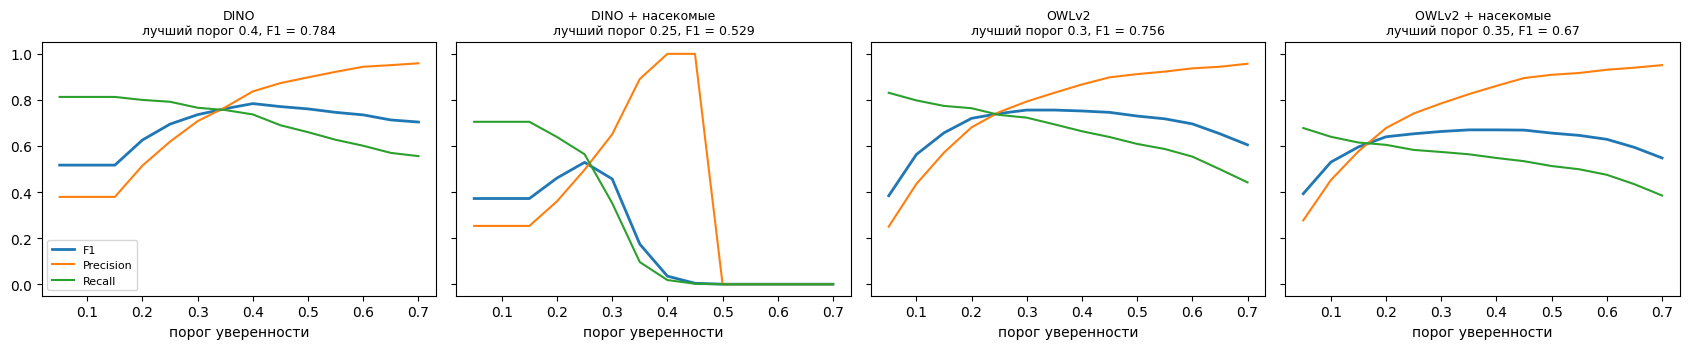

In [27]:
import matplotlib.pyplot as plt

thresholds = [round(0.05 * i, 2) for i in range(1, 15)]
runs = [("DINO", preds_dino), ("DINO + насекомые", preds_dino_neg),
        ("OWLv2", preds_owl), ("OWLv2 + насекомые", preds_owl_neg)]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)

for ax, (name, p) in zip(axes, runs):
    rows = [evaluate(cut(p, t)) for t in thresholds]
    ax.plot(thresholds, [r["F1"] for r in rows], label="F1", linewidth=2)
    ax.plot(thresholds, [r["P"] for r in rows], label="Precision")
    ax.plot(thresholds, [r["R"] for r in rows], label="Recall")
    best = max(range(len(rows)), key=lambda i: rows[i]["F1"])
    ax.set_title(f"{name}\nлучший порог {thresholds[best]}, F1 = {rows[best]['F1']}", fontsize=9)
    ax.set_xlabel("порог уверенности")
    print(name, "лучший порог", thresholds[best], rows[best])

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("threshold_sweep.png", dpi=150)
plt.show()

Результат E2 (порог):
- DINO: лучший порог 0.40, F1 0.762 → 0.784 (+2 п.п.). Стандартный порог 0.35 почти оптимальный.
- OWLv2: лучший порог 0.30, F1 0.563 → 0.756 (+19 п.п.). Порог 0.10 был сильно занижен:
  у OWLv2 уверенность в целом ниже, и при низком пороге проходит много лишних рамок.
Ожидание подтвердилось частично: для DINO угадали (0.30-0.40), для OWLv2 оптимум оказался
выше, чем думали (0.30, а не 0.15-0.25).
Даже с лучшим порогом оба детектора уступают Qwen (0.78 и 0.76 против 0.88).
Порог подобран на нашем же наборе, поэтому эти цифры немного оптимистичны.

7.2. E3: удаление дублирующихся рамок (NMS)

In [26]:
from torchvision.ops import nms

def remove_duplicates(preds, iou_thr=0.5):
    result = {}
    for pid, boxes in preds.items():
        if len(boxes) < 2:
            result[pid] = boxes
            continue
        xyxy = torch.tensor([[b["left"], b["top"], b["left"] + b["width"], b["top"] + b["height"]]
                             for b in boxes])
        scores = torch.tensor([b.get("score", 1.0) for b in boxes])   # у Qwen уверенности нет
        keep = nms(xyxy, scores, iou_thr).tolist()
        result[pid] = [boxes[i] for i in sorted(keep)]
    return result

print("DINO  0.35       ", evaluate(cut(preds_dino, 0.35)))
print("DINO  0.35 + NMS ", evaluate(remove_duplicates(cut(preds_dino, 0.35))))
print("OWLv2 0.10       ", evaluate(cut(preds_owl, 0.10)))
print("OWLv2 0.10 + NMS ", evaluate(remove_duplicates(cut(preds_owl, 0.10))))
print("Qwen base        ", evaluate(preds_qwen_base))
print("Qwen base + NMS  ", evaluate(remove_duplicates(preds_qwen_base)))

DINO  0.35        {'F1': 0.762, 'P': 0.768, 'R': 0.756, 'TP': 385, 'FP': 116, 'FN': 124}
DINO  0.35 + NMS  {'F1': 0.771, 'P': 0.789, 'R': 0.754, 'TP': 384, 'FP': 103, 'FN': 125}
OWLv2 0.10        {'F1': 0.563, 'P': 0.435, 'R': 0.798, 'TP': 406, 'FP': 528, 'FN': 103}
OWLv2 0.10 + NMS  {'F1': 0.64, 'P': 0.541, 'R': 0.784, 'TP': 399, 'FP': 338, 'FN': 110}
Qwen base         {'F1': 0.86, 'P': 0.912, 'R': 0.813, 'TP': 414, 'FP': 40, 'FN': 95}
Qwen base + NMS   {'F1': 0.86, 'P': 0.912, 'R': 0.813, 'TP': 414, 'FP': 40, 'FN': 95}


Результат E3 (удаление дублей):
- OWLv2: F1 0.563 → 0.640 (+8 п.п.), лишних рамок 528 → 338. Подтвердилось:
  OWLv2 часто ставит несколько рамок на одну бабочку.
- DINO: 0.762 → 0.771 (+1 п.п.), дублей мало.
- Qwen: без изменений, дублей у него нет.
Ожидание подтвердилось полностью.

## 8. Итог
Общая таблица всех вариантов, выбираем лучший по F1@0.5 (при равенстве - более быстрый).
Отдельно смотрим, где ошибается лучшая модель: фото без бабочек, с одной и с несколькими.

8.1. Итоговая таблица

In [28]:
variants = {
    "Qwen строгий промпт":       (qwen_preds, "qwen_strict"),
    "Qwen обычный промпт":       (preds_qwen_base, "qwen_base"),
    "DINO порог 0.35":           (cut(preds_dino, 0.35), "gdino"),
    "DINO порог 0.40":           (cut(preds_dino, 0.40), "gdino"),
    "DINO 0.35 + NMS":           (remove_duplicates(cut(preds_dino, 0.35)), "gdino"),
    "DINO + насекомые, 0.35":    (cut(preds_dino_neg, 0.35), "gdino_neg"),
    "OWLv2 порог 0.10":          (cut(preds_owl, 0.10), "owlv2"),
    "OWLv2 порог 0.30":          (cut(preds_owl, 0.30), "owlv2"),
    "OWLv2 0.10 + NMS":          (remove_duplicates(cut(preds_owl, 0.10)), "owlv2"),
    "OWLv2 0.30 + NMS":          (remove_duplicates(cut(preds_owl, 0.30)), "owlv2"),
    "OWLv2 + насекомые, 0.10":   (cut(preds_owl_neg, 0.10), "owlv2_neg"),
}

def mean_time(file_name):
    t = [json.loads(l)["time_s"] for l in open(f"pred_{file_name}.jsonl")]
    return round(sum(t) / len(t), 2)

table = []
for name, (p, file_name) in variants.items():
    m5, m75 = evaluate(p, 0.5), evaluate(p, 0.75)
    empty = [pid for pid in golden if not golden[pid]]
    table.append({"вариант": name, "F1@0.5": m5["F1"], "P": m5["P"], "R": m5["R"],
                  "F1@0.75": m75["F1"], "TP": m5["TP"], "FP": m5["FP"], "FN": m5["FN"],
                  "лишние рамки на пустых": sum(len(p.get(pid, [])) for pid in empty),
                  "с/фото": mean_time(file_name)})

leaderboard = pd.DataFrame(table).sort_values(["F1@0.5", "с/фото"], ascending=[False, True])
leaderboard.to_csv("leaderboard.csv", index=False)
leaderboard

,вариант,F1@0.5,P,R,F1@0.75,TP,FP,FN,лишние рамки на пустых,с/фото
0,Qwen строгий промпт,0.880,0.946,0.823,0.702,419,24,90,8,2.67
1,Qwen обычный промпт,0.860,0.912,0.813,0.692,414,40,95,24,2.64
3,DINO порог 0.40,0.784,0.837,0.737,0.675,375,73,134,41,0.53
9,OWLv2 0.30 + NMS,0.775,0.839,0.719,0.525,366,70,143,5,1.11
4,DINO 0.35 + NMS,0.771,0.789,0.754,0.661,384,103,125,63,0.53
2,DINO порог 0.35,0.762,0.768,0.756,0.657,385,116,124,64,0.53
7,OWLv2 порог 0.30,0.756,0.793,0.723,0.522,368,96,141,5,1.11
8,OWLv2 0.10 + NMS,0.640,0.541,0.784,0.421,399,338,110,14,1.11
6,OWLv2 порог 0.10,0.563,0.435,0.798,0.398,406,528,103,16,1.11
10,"OWLv2 + насекомые, 0.10",0.530,0.452,0.640,0.356,326,396,183,0,1.00


8.2. Где ошибается лучшая модель: по числу бабочек на фото

In [29]:
best = qwen_preds
for group, ids in [("без бабочек", [p for p in golden if len(golden[p]) == 0]),
                   ("1 бабочка",   [p for p in golden if len(golden[p]) == 1]),
                   ("2+ бабочки",  [p for p in golden if len(golden[p]) >= 2])]:
    TP = FP = FN = 0
    for pid in ids:
        tp, fp, fn = count_on_photo(golden[pid], best.get(pid, []))
        TP += tp; FP += fp; FN += fn
    print(f"{group}: {len(ids)} фото, TP={TP}, FP={FP}, FN={FN}")

без бабочек: 60 фото, TP=0, FP=8, FN=0
1 бабочка: 275 фото, TP=273, FP=4, FN=2
2+ бабочки: 65 фото, TP=146, FP=12, FN=88


Итог:
Лучшая конфигурация по F1@0.5 - Qwen3-VL-2B со строгим промптом:
F1@0.5 = 0.880 (P 0.946, R 0.823), F1@0.75 = 0.702, 2.7 с/фото на T4, ошибок 0.
Её фиксируем для экзамена: версия весов 89644892e4d85e24eaac8bacfd4f463576704203, float16, фото до 1024 px,
строгий промпт, без порога и без NMS.

Лучшие варианты детекторов после подбора порога и NMS: DINO 0.784, OWLv2 0.775.
Они в 3-5 раз быстрее, но уступают Qwen на 10 п.п. и чаще ставят рамки на пустые фото
(DINO 41 рамка, Qwen 8).

Где ошибается Qwen:
- 1 бабочка (275 фото): почти идеально, 2 пропуска и 4 лишние рамки;
- без бабочек (60 фото): 8 лишних рамок;
- 2+ бабочки (65 фото): 88 пропусков из 90 всех пропусков.
  Слабое место - скопления: модель обводит не всех бабочек, если их много и они перекрываются.

Проверка: результаты совпадают с первой версией кода (те же TP/FP/FN во всех вариантах)

8.3. Скачать предсказания и результаты

In [30]:
!zip -q results_new.zip pred_*.jsonl leaderboard.csv threshold_sweep.png
from google.colab import files
files.download("results_new.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>